# Experiment 7: Feature Scaling - Normalization and Standardization

## Import libraries

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine, load_breast_cancer
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

sns.set_theme(style="whitegrid")
np.random.seed(42)
RS = 42

## Load dataset

(178, 13) | classes: [0 1 2]


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


,mean,std,min,max
alcohol,13.001,0.812,11.03,14.83
malic_acid,2.336,1.117,0.74,5.80
ash,2.367,0.274,1.36,3.23
alcalinity_of_ash,19.495,3.340,10.60,30.00
magnesium,99.742,14.282,70.00,162.00
total_phenols,2.295,0.626,0.98,3.88
flavanoids,2.029,0.999,0.34,5.08
nonflavanoid_phenols,0.362,0.124,0.13,0.66
proanthocyanins,1.591,0.572,0.41,3.58
color_intensity,5.058,2.318,1.28,13.00


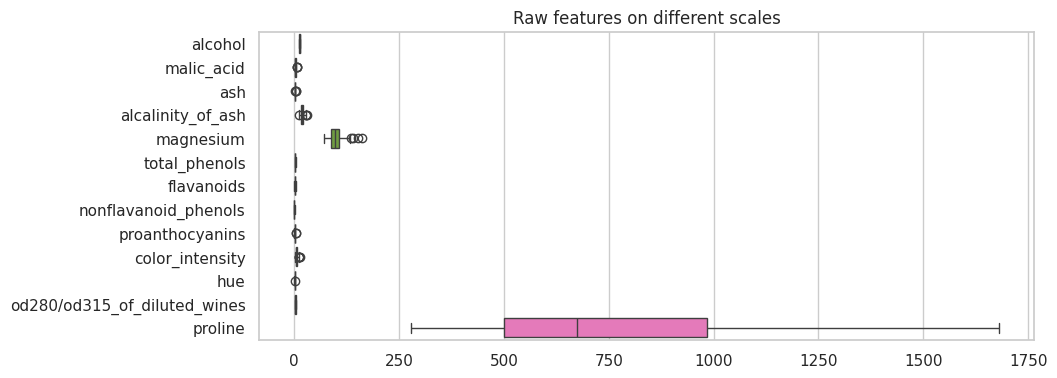

In [2]:
wine = load_wine(as_frame=True)
X, y = wine.data, wine.target
print(X.shape, "| classes:", np.unique(y))
display(X.head())

display(X.describe().T[["mean", "std", "min", "max"]].round(3))

plt.figure(figsize=(10, 4))
sns.boxplot(data=X, orient="h")
plt.title("Raw features on different scales")
plt.show()

## Min-Max normalization (manual)

In [3]:
X_minmax_manual = (X - X.min()) / (X.max() - X.min())
X_minmax_manual.describe().T[["min", "max", "mean", "std"]].round(3)

,min,max,mean,std
alcohol,0.0,1.0,0.519,0.214
malic_acid,0.0,1.0,0.315,0.221
ash,0.0,1.0,0.538,0.147
alcalinity_of_ash,0.0,1.0,0.459,0.172
magnesium,0.0,1.0,0.323,0.155
total_phenols,0.0,1.0,0.453,0.216
flavanoids,0.0,1.0,0.356,0.211
nonflavanoid_phenols,0.0,1.0,0.437,0.235
proanthocyanins,0.0,1.0,0.373,0.181
color_intensity,0.0,1.0,0.322,0.198


## Min-Max normalization (scikit-learn)

In [4]:
mm = MinMaxScaler()
X_minmax = pd.DataFrame(mm.fit_transform(X), columns=X.columns)
print("Matches manual calculation:", np.allclose(X_minmax, X_minmax_manual))
X_minmax.head()

Matches manual calculation: True


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,0.842105,0.191700,0.572193,0.257732,0.619565,0.627586,0.573840,0.283019,0.593060,0.372014,0.455285,0.970696,0.561341
1,0.571053,0.205534,0.417112,0.030928,0.326087,0.575862,0.510549,0.245283,0.274448,0.264505,0.463415,0.780220,0.550642
2,0.560526,0.320158,0.700535,0.412371,0.336957,0.627586,0.611814,0.320755,0.757098,0.375427,0.447154,0.695971,0.646933
3,0.878947,0.239130,0.609626,0.319588,0.467391,0.989655,0.664557,0.207547,0.558360,0.556314,0.308943,0.798535,0.857347
4,0.581579,0.365613,0.807487,0.536082,0.521739,0.627586,0.495781,0.490566,0.444795,0.259386,0.455285,0.608059,0.325963


## Standardization (manual)

In [5]:
X_std_manual = (X - X.mean()) / X.std(ddof=0)
X_std_manual.describe().T[["mean", "std"]].round(3)

,mean,std
alcohol,0.0,1.003
malic_acid,0.0,1.003
ash,-0.0,1.003
alcalinity_of_ash,-0.0,1.003
magnesium,-0.0,1.003
total_phenols,0.0,1.003
flavanoids,0.0,1.003
nonflavanoid_phenols,-0.0,1.003
proanthocyanins,-0.0,1.003
color_intensity,-0.0,1.003


## Standardization (scikit-learn)

In [6]:
ss = StandardScaler()
X_std = pd.DataFrame(ss.fit_transform(X), columns=X.columns)
print("Matches manual calculation:", np.allclose(X_std, X_std_manual))
X_std.head()

Matches manual calculation: True


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,1.518613,-0.562250,0.232053,-1.169593,1.913905,0.808997,1.034819,-0.659563,1.224884,0.251717,0.362177,1.847920,1.013009
1,0.246290,-0.499413,-0.827996,-2.490847,0.018145,0.568648,0.733629,-0.820719,-0.544721,-0.293321,0.406051,1.113449,0.965242
2,0.196879,0.021231,1.109334,-0.268738,0.088358,0.808997,1.215533,-0.498407,2.135968,0.269020,0.318304,0.788587,1.395148
3,1.691550,-0.346811,0.487926,-0.809251,0.930918,2.491446,1.466525,-0.981875,1.032155,1.186068,-0.427544,1.184071,2.334574
4,0.295700,0.227694,1.840403,0.451946,1.281985,0.808997,0.663351,0.226796,0.401404,-0.319276,0.362177,0.449601,-0.037874


## Robust scaling

In [7]:
rs = RobustScaler()
X_robust = pd.DataFrame(rs.fit_transform(X), columns=X.columns)
X_robust.describe().T[["mean", "std", "min", "max"]].round(3)

,mean,std,min,max
alcohol,-0.038,0.617,-1.536,1.354
malic_acid,0.318,0.755,-0.760,2.659
ash,0.019,0.789,-2.878,2.504
alcalinity_of_ash,-0.001,0.777,-2.070,2.442
magnesium,0.092,0.752,-1.474,3.368
total_phenols,-0.057,0.592,-1.300,1.442
flavanoids,-0.063,0.598,-1.075,1.763
nonflavanoid_phenols,0.130,0.743,-1.254,1.910
proanthocyanins,0.051,0.818,-1.636,2.893
color_intensity,0.124,0.778,-1.144,2.789


## Comparison of scaled statistics

,raw_mean,raw_std,minmax_min,minmax_max,std_mean,std_std
alcohol,13.001,0.812,0.0,1.0,0.0,1.0
malic_acid,2.336,1.117,0.0,1.0,0.0,1.0
ash,2.367,0.274,0.0,1.0,-0.0,1.0
alcalinity_of_ash,19.495,3.340,0.0,1.0,-0.0,1.0
magnesium,99.742,14.282,0.0,1.0,-0.0,1.0
total_phenols,2.295,0.626,0.0,1.0,-0.0,1.0
flavanoids,2.029,0.999,0.0,1.0,0.0,1.0
nonflavanoid_phenols,0.362,0.124,0.0,1.0,-0.0,1.0
proanthocyanins,1.591,0.572,0.0,1.0,-0.0,1.0
color_intensity,5.058,2.318,0.0,1.0,-0.0,1.0


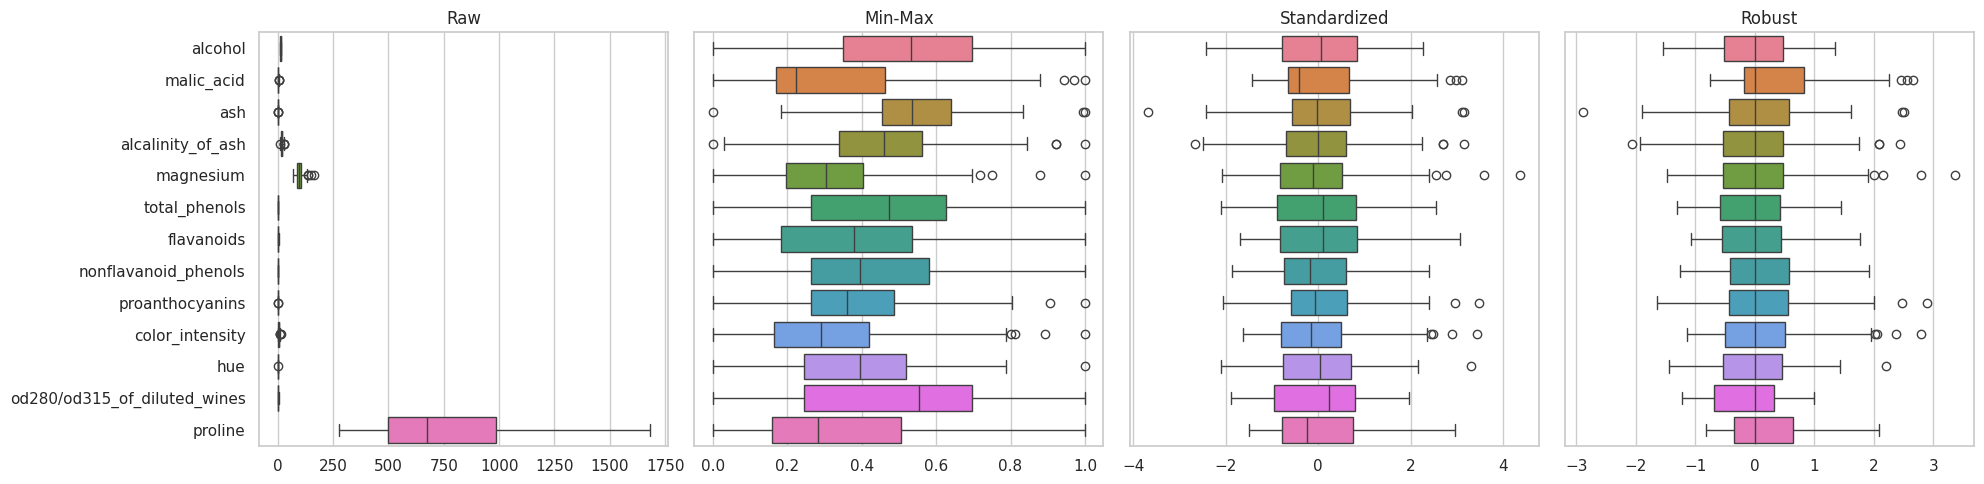

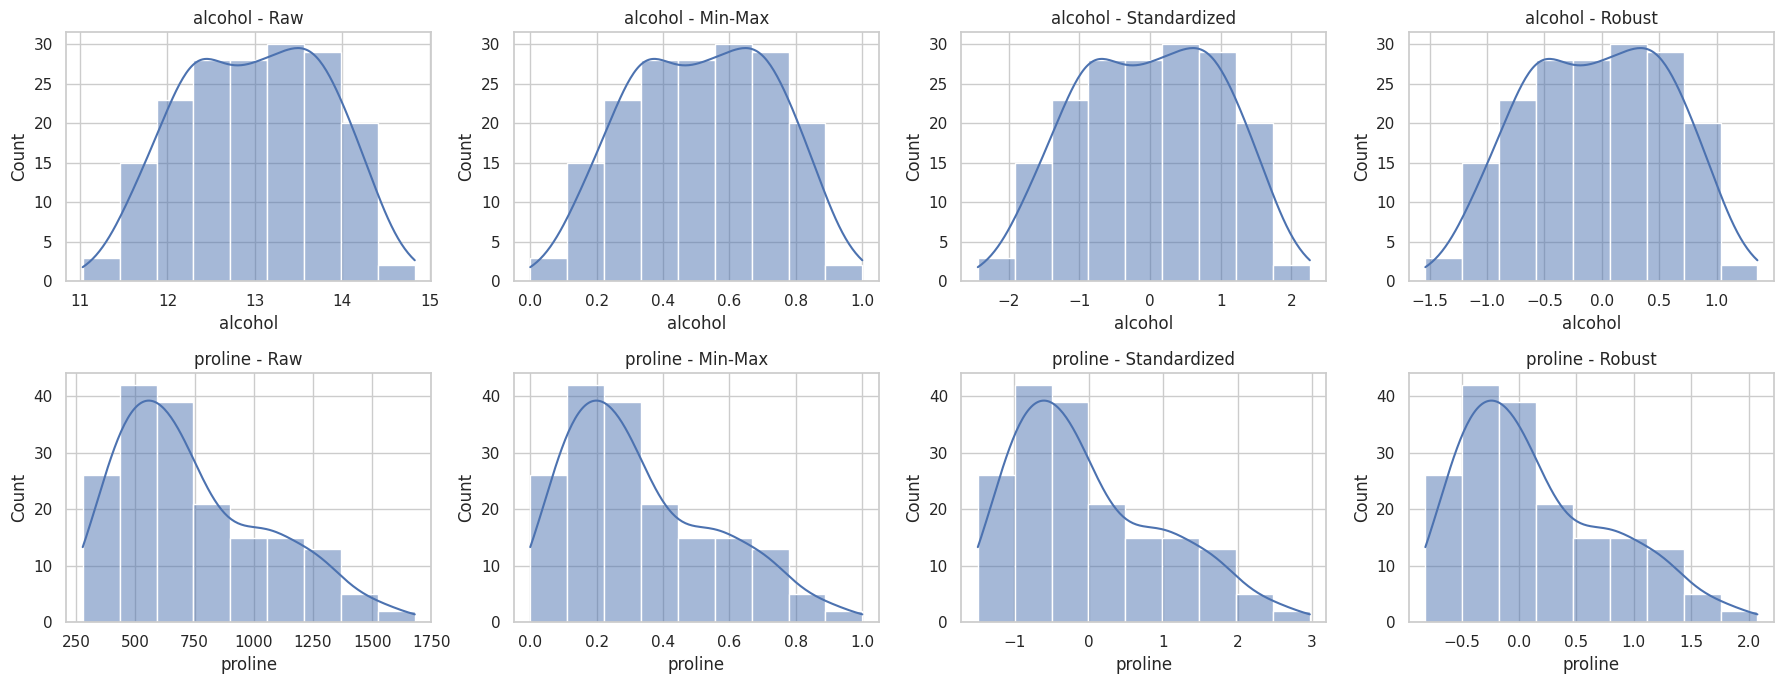

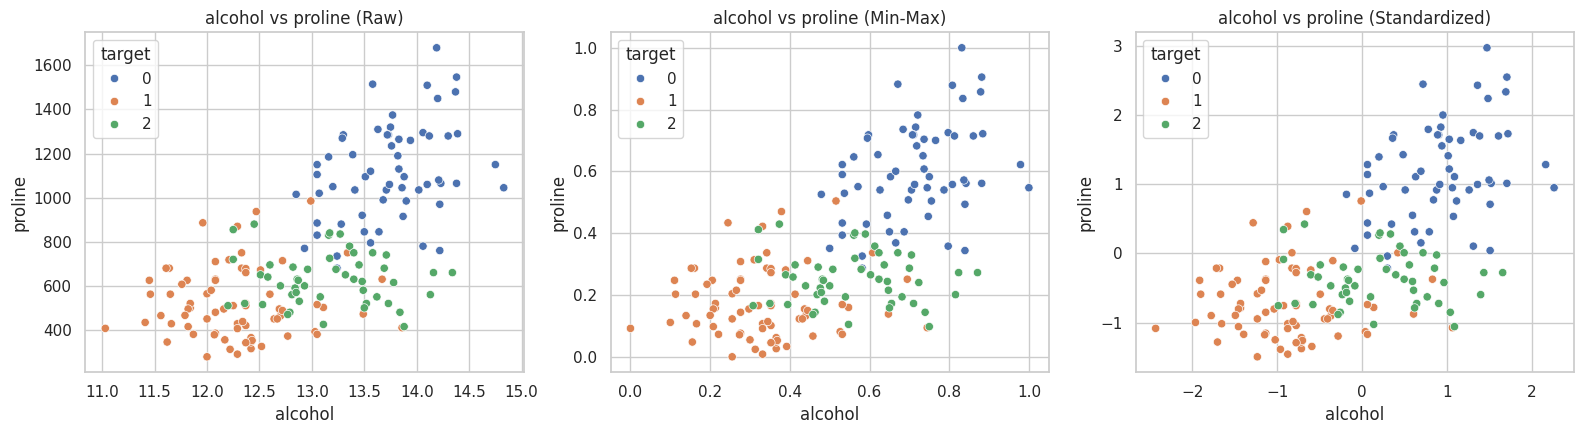

In [8]:
comparison = pd.DataFrame({
    "raw_mean": X.mean(), "raw_std": X.std(),
    "minmax_min": X_minmax.min(), "minmax_max": X_minmax.max(),
    "std_mean": X_std.mean(), "std_std": X_std.std(ddof=0),
})
display(comparison.round(3))

fig, axes = plt.subplots(1, 4, figsize=(20, 5), sharex=False)
for ax, (title, data) in zip(axes, [("Raw", X), ("Min-Max", X_minmax), ("Standardized", X_std), ("Robust", X_robust)]):
    sns.boxplot(data=data, orient="h", ax=ax)
    ax.set_title(title)
    if title != "Raw":
        ax.set_yticklabels([])
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for row, col in zip(axes, ["alcohol", "proline"]):
    for ax, (title, data) in zip(row, [("Raw", X), ("Min-Max", X_minmax), ("Standardized", X_std), ("Robust", X_robust)]):
        sns.histplot(data[col], kde=True, ax=ax)
        ax.set_title(f"{col} - {title}")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (title, data) in zip(axes, [("Raw", X), ("Min-Max", X_minmax), ("Standardized", X_std)]):
    sns.scatterplot(x=data["alcohol"], y=data["proline"], hue=y, palette="deep", ax=ax)
    ax.set_title(f"alcohol vs proline ({title})")
plt.tight_layout()
plt.show()

## Inverse transformation

In [9]:
restored = ss.inverse_transform(X_std)
print("Standardization reversible:", np.allclose(restored, X.values))
restored = mm.inverse_transform(X_minmax)
print("Min-Max reversible:", np.allclose(restored, X.values))

Standardization reversible: True
Min-Max reversible: True


## Train-test split and leakage-free scaling

In [10]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=RS, stratify=y)
mm_s = MinMaxScaler().fit(X_train)
ss_s = StandardScaler().fit(X_train)
Xtr_mm, Xte_mm = mm_s.transform(X_train), mm_s.transform(X_test)
Xtr_ss, Xte_ss = ss_s.transform(X_train), ss_s.transform(X_test)
print("Train min/max after Min-Max:", Xtr_mm.min().round(3), Xtr_mm.max().round(3))
print("Test  min/max after Min-Max:", Xte_mm.min().round(3), Xte_mm.max().round(3))
print("Train mean after standardization:", Xtr_ss.mean().round(3))

Train min/max after Min-Max: 0.0 1.0
Test  min/max after Min-Max: -0.003 1.394
Train mean after standardization: 0.0


## Impact on model performance (wine dataset)

,raw,min-max,standardized
model,,,
KNN,0.7222,0.963,0.9444
SVM (RBF),0.6667,1.000,0.9815
Logistic Regression,0.9630,1.000,0.9815
Decision Tree,0.9630,0.963,0.9630


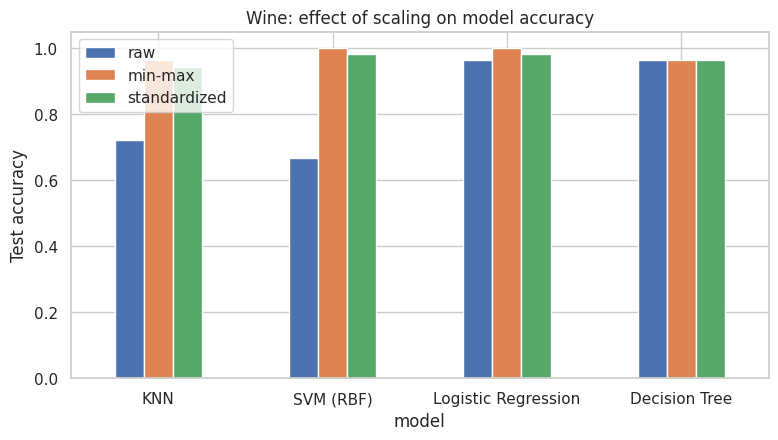

In [11]:
models = {
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "SVM (RBF)": SVC(random_state=RS),
    "Logistic Regression": LogisticRegression(max_iter=5000, random_state=RS),
    "Decision Tree": DecisionTreeClassifier(random_state=RS),
}
rows = []
for name, model in models.items():
    raw = model.fit(X_train, y_train).score(X_test, y_test)
    mmx = model.fit(Xtr_mm, y_train).score(Xte_mm, y_test)
    stdz = model.fit(Xtr_ss, y_train).score(Xte_ss, y_test)
    rows.append([name, raw, mmx, stdz])
perf = pd.DataFrame(rows, columns=["model", "raw", "min-max", "standardized"]).set_index("model")
display(perf.round(4))

perf.plot(kind="bar", figsize=(9, 4.5), rot=0)
plt.ylabel("Test accuracy"); plt.ylim(0, 1.05)
plt.title("Wine: effect of scaling on model accuracy")
plt.show()

## Cross-validated comparison (scaling inside a pipeline)

In [12]:
rows = []
for name, model in models.items():
    raw = cross_val_score(model, X, y, cv=5).mean()
    mmx = cross_val_score(make_pipeline(MinMaxScaler(), model), X, y, cv=5).mean()
    stdz = cross_val_score(make_pipeline(StandardScaler(), model), X, y, cv=5).mean()
    rows.append([name, raw, mmx, stdz])
cv_perf = pd.DataFrame(rows, columns=["model", "raw", "min-max", "standardized"]).set_index("model")
cv_perf.round(4)

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 5000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=5000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,raw,min-max,standardized
model,,,
KNN,0.6913,0.9495,0.9494
SVM (RBF),0.6635,0.9776,0.9833
Logistic Regression,0.9611,0.9776,0.9832
Decision Tree,0.8654,0.8654,0.8654


## Second real-world dataset: breast cancer

,raw,min-max,standardized
model,,,
KNN,0.9279,0.9719,0.9649
SVM (RBF),0.9122,0.9754,0.9736
Logistic Regression,0.9508,0.9613,0.9807
Decision Tree,0.9173,0.9173,0.9173


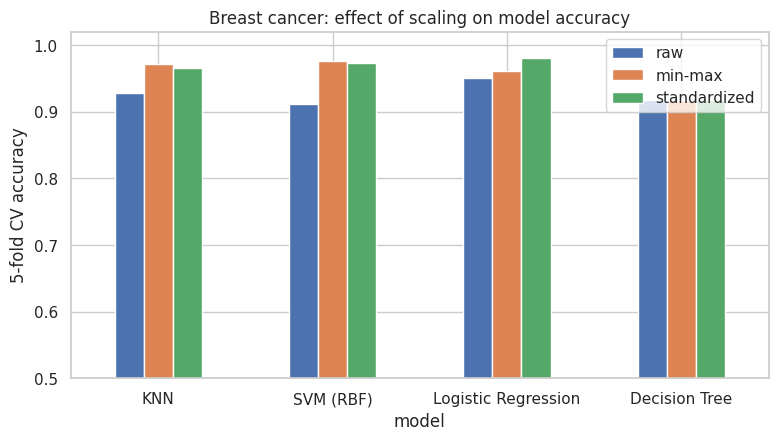

In [13]:
bc = load_breast_cancer(as_frame=True)
Xb, yb = bc.data, bc.target
rows = []
for name, model in models.items():
    raw = cross_val_score(model, Xb, yb, cv=5).mean()
    mmx = cross_val_score(make_pipeline(MinMaxScaler(), model), Xb, yb, cv=5).mean()
    stdz = cross_val_score(make_pipeline(StandardScaler(), model), Xb, yb, cv=5).mean()
    rows.append([name, raw, mmx, stdz])
bc_perf = pd.DataFrame(rows, columns=["model", "raw", "min-max", "standardized"]).set_index("model")
display(bc_perf.round(4))

bc_perf.plot(kind="bar", figsize=(9, 4.5), rot=0)
plt.ylabel("5-fold CV accuracy"); plt.ylim(0.5, 1.02)
plt.title("Breast cancer: effect of scaling on model accuracy")
plt.show()

## Effect of scaling on KNN distance

In [14]:
a, b = X.iloc[0].values, X.iloc[1].values
print("Euclidean distance (raw):", np.linalg.norm(a - b).round(3))
print("Euclidean distance (standardized):", np.linalg.norm(X_std.iloc[0].values - X_std.iloc[1].values).round(3))
contrib = pd.DataFrame({"raw_sq_diff": (a - b) ** 2, "std_sq_diff": (X_std.iloc[0].values - X_std.iloc[1].values) ** 2}, index=X.columns)
(contrib / contrib.sum() * 100).round(2).sort_values("raw_sq_diff", ascending=False).head(5)

Euclidean distance (raw): 31.265
Euclidean distance (standardized): 3.498


,raw_sq_diff,std_sq_diff
magnesium,74.58,29.38
proline,23.02,0.02
alcalinity_of_ash,1.98,14.27
color_intensity,0.16,2.43
alcohol,0.11,13.23
